# Red Cedar — Dataset Analysis

Three analyses help you understand a dataset before training:
1. **PCA** — how many independent dimensions carry real signal
2. **Mutual information** — which directions in the data predict the class label
3. **Quantum resource estimation** — about how many qubits a model needs

The last sections compare two datasets and show how to analyze your own CSV file. Run the setup cell first; after that, each section can be run on its own.

In [1]:
import redcedar
import matplotlib.pyplot as plt

# Connect to the server
# Reads REDCEDAR_URL and REDCEDAR_API_KEY from environment, or pass explicitly:
# client = redcedar.connect(url="http://127.0.0.1:8002", api_key="your-key")
# With the Red Cedar source installed (pip install -e), local mode calls it directly:
# client = redcedar.connect(local=True)
client = redcedar.connect()
print(f"Red Cedar SDK v{redcedar.__version__}")
status = client.status()
print(f"Server: {client.url or 'local mode, in this process'} (version {status['server_version'] or 'unknown'}, ok={status['ok']})")

Red Cedar SDK v0.93.0
Server: http://127.0.0.1:8002 (version 0.92-18-g1706a0dc-dirty, ok=True)


## 1. Datasets on the server

Each dataset's `id` is what you pass to the analysis and training functions.

In [2]:
datasets = client.datasets.list()
print(f"{'id':22s} {'name':45s} {'rows':>6s} {'classes':>8s}")
for ds in datasets:
    print(f"{ds['id']:22s} {ds['name'][:45]:45s} {str(ds.get('rows', '?')):>6s} {str(ds.get('classes', '?')):>8s}")

dataset = "wdbc"
print(f"\nAnalyzing: {dataset}")

id                     name                                            rows  classes
clinical_trial_v1      Clinical Trial V1 (Synthetic - 7 features)       765        2
clinical_trial_v2      Clinical Trial V2 (Synthetic - 5 features)       765        2
diabetes               Pima Diabetes                                    768        2
iris                   Iris                                             150        3
mnist_784              MNIST Full (70k)                               70000        4
mnist_small            MNIST Small (400 samples)                        400        4
random_gene_expression Random Gene Expression  (Synthetic)                ?        2
wdbc                   WDBC (Breast Cancer)                             569        2
wine                   Wine                                             178        3
airfoil_self_noise     Airfoil Self-Noise                              1503        ?
diabetes_progression   Diabetes Progression                      

## 2. PCA: how many dimensions matter

Principal component analysis finds the directions in which the data varies most. If a few components explain most of the variance, the data can be compressed to fewer features (and qubits) with little loss.

  [100%] Done.

30 features, 569 samples
Components for 90% of the variance: 7
Components for 95% of the variance: 10


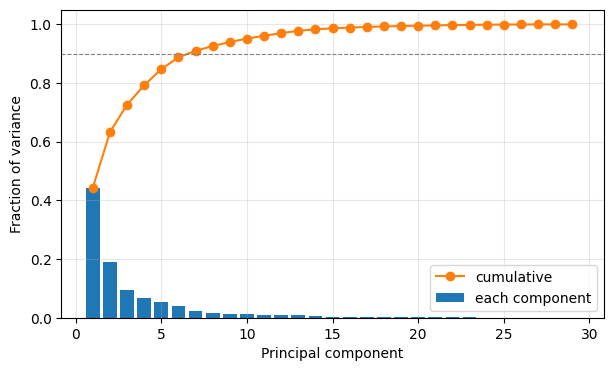

In [3]:
pca = client.analysis.pca(dataset, verbose=True)

print(f"\n{pca['features']} features, {pca['samples']} samples")
print(f"Components for 90% of the variance: {pca['thresholds']['90']}")
print(f"Components for 95% of the variance: {pca['thresholds']['95']}")

n = range(1, len(pca["variance_ratios"]) + 1)
plt.figure(figsize=(7, 4))
plt.bar(n, pca["variance_ratios"], label="each component")
plt.plot(n, pca["cumulative_variance"], "o-", color="C1", label="cumulative")
plt.axhline(0.9, color="gray", ls="--", lw=0.8)
plt.xlabel("Principal component")
plt.ylabel("Fraction of variance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 3. Mutual information: what predicts the class

Mutual information measures how much knowing a value tells you about the class label. The analysis first applies PCA, the same way training prepares the data, and then scores each principal component (`PC1`, `PC2`, ...). Components with high scores carry the most signal for classification; they are not always the ones with the most variance.

  [100%] Done.

Total MI: 1.3392
Components for 90% of the total MI: 17


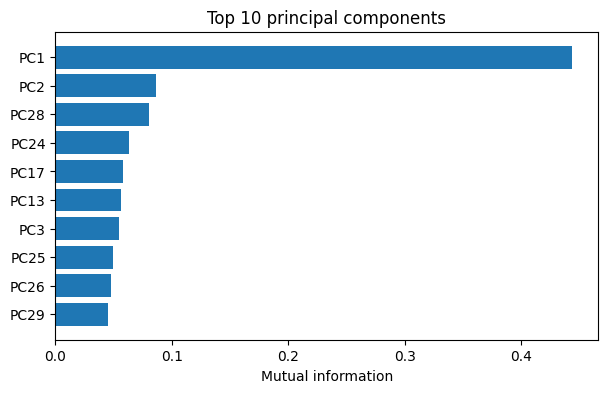

In [4]:
mi = client.analysis.mi(dataset, verbose=True)

print(f"\nTotal MI: {mi['total_mi']:.4f}")
print(f"Components for 90% of the total MI: {mi['thresholds']['90']}")

top = mi["ranked_features"][:10]
plt.figure(figsize=(7, 4))
plt.barh([f["feature_name"] for f in top], [f["mi_score"] for f in top])
plt.gca().invert_yaxis()
plt.xlabel("Mutual information")
plt.title("Top 10 principal components")
plt.show()

## 4. Quantum resource estimation: how many qubits

The estimate encodes the data with more and more qubits and checks the best accuracy any model could reach at each size: once two samples with different classes look identical after encoding, no model can tell them apart. The estimate is the number of data qubits where that limit reaches 100%, plus the qubits needed for the class label, averaged over 10 random train/test splits.

  [100%] Done.

Estimated qubits: 16 +/- 1.4


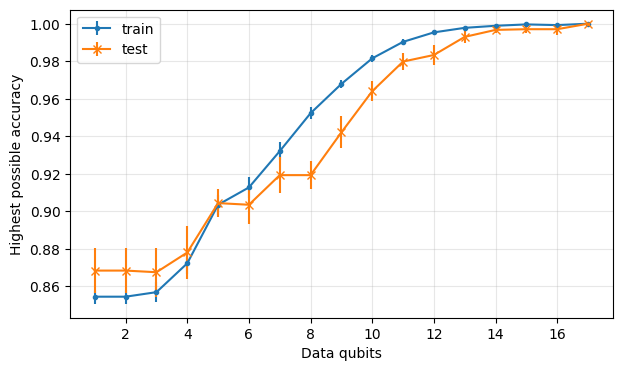

In [5]:
qre = client.analysis.qre(dataset, verbose=True)

print(f"\nEstimated qubits: {qre['estimatedQubits']} +/- {qre['standardDeviation']:.1f}")
if qre.get("warning_message"):
    print("Note:", qre["warning_message"])

points = qre["plotData"]
qubits = [p["Number of Qubits"] for p in points]
plt.figure(figsize=(7, 4))
plt.errorbar(qubits, [p["Train"] for p in points], yerr=[p["Train sem"] for p in points], marker=".", label="train")
plt.errorbar(qubits, [p["Test"] for p in points], yerr=[p["Test sem"] for p in points], marker="x", label="test")
plt.xlabel("Data qubits")
plt.ylabel("Highest possible accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 5. Comparing datasets

The same three analyses side by side for two datasets: the breast cancer data above and a synthetic clinical trial dataset stored on the server.

In [6]:
rows = []
for ds_id in ["wdbc", "clinical_trial_v1"]:
    p = client.analysis.pca(ds_id)
    m = client.analysis.mi(ds_id)
    q = client.analysis.qre(ds_id)
    rows.append((ds_id, p["features"], p["samples"], p["thresholds"]["90"], m["total_mi"], q["estimatedQubits"]))

print(f"{'dataset':20s} {'features':>8s} {'samples':>8s} {'PCA 90%':>8s} {'total MI':>9s} {'qubits':>7s}")
for r in rows:
    print(f"{r[0]:20s} {r[1]:8d} {r[2]:8d} {r[3]:8d} {r[4]:9.4f} {r[5]:7d}")

dataset              features  samples  PCA 90%  total MI  qubits
wdbc                       30      569        7    1.3392      16
clinical_trial_v1           7      974        6    0.0373      20


## 6. Your own data

Upload a CSV file and analyze it like any other dataset. The last column is the class label; a header row is optional. The upload returns an ID that works with the analysis functions and with `client.training.run()`.

This cell writes a small example file (four random features; the class depends only on the first two) so the section runs as is; replace `csv_path` with your own file. One principal component should carry nearly all of the mutual information.

In [7]:
import csv, os, random, tempfile

csv_path = os.path.join(tempfile.gettempdir(), "redcedar_example.csv")
random.seed(0)
with open(csv_path, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["x1", "x2", "x3", "x4", "label"])
    for _ in range(300):
        x = [round(random.random(), 3) for _ in range(4)]
        w.writerow(x + ["A" if x[0] + x[1] > 1 else "B"])

my_dataset = client.datasets.upload(csv_path)
print(f"Uploaded {os.path.basename(csv_path)} as {my_dataset}")

mi = client.analysis.mi(my_dataset)
for f in mi["ranked_features"]:
    print(f"  {f['feature_name']}: MI={f['mi_score']:.4f} ({f['mi_percent']:.1f}%)")

Uploaded redcedar_example.csv as 86a6b815-f688-4cd9-8a9c-6d97f1df2913
  PC2: MI=0.3059 (91.1%)
  PC3: MI=0.0215 (6.4%)
  PC1: MI=0.0085 (2.5%)
